# Rossmann Store Sales — Phase 4.6: Feature Rebuild

Three structural problems found when reviewing why Phases 2-4 gained so little over the Phase 1 baseline:

1. **Train/serve mismatch.** Training rows got rolling features "as of yesterday"; validation rows got them frozen at a cutoff and up to 42 days stale. `HorizonDay` was supposed to signal that staleness but was hard-coded to `0` for every training row, so it was constant, unlearnable, and measured **exactly 0.000000 importance** in both tree models.
2. **`SalesYearAgo` conflated two quantities** — a real 364-day-ago observation (87% of rows) and the Phase 1 baseline lookup where that was missing (13%) — with no flag distinguishing them. HGB's permutation importance for it was **-0.185**, the most negative of any feature, which suggested the column was actively hurting. Ablation E tests that suggestion directly rather than trusting it.
3. **Missing known-schedule features**: promo/holiday proximity, closure-adjacent days, and reopening after a long shutdown (the 181-store blackout the EDA found but never exploited).

Run as an **ablation**, one change at a time, so we learn which fix actually pays rather than shipping a bundle and guessing. HGB is the probe throughout (~15s per fit) with Phase 3's hyperparameters held fixed, and every number below is uncalibrated single-model — Phase 4.5's calibration and ensembling stack on top separately. `test.csv` stays unseen until Phase 5.

In [1]:
import json
import time
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
pio.templates.default = "plotly_white"

from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

from rossmann_features import (
    prepare_store_table, add_features, NUMERIC_COLS, ROLLING_WINDOWS,
    add_rolling_features_training, add_rolling_features_frozen,
    add_yearago_lag, fit_store_dow_promo_mean, predict_store_dow_promo_mean,
    fit_store_target_encoding, add_store_target_encoding,
)
import rossmann_features_v2 as f2
from rossmann_nn import rmspe

train = pd.read_csv("train.csv", parse_dates=["Date"], low_memory=False, dtype={"StateHoliday": str})
store = pd.read_csv("store.csv")
store_prepared = prepare_store_table(store)

with open("phase1_split_config.json") as f:
    val_start = pd.Timestamp(json.load(f)["val_start"])
train_fold = add_features(train[train["Date"] < val_start].copy(), store_prepared)
val_fold = add_features(train[train["Date"] >= val_start].copy(), store_prepared)
train_fold_open = train_fold[train_fold["Open"] == 1]
train_fit = train_fold[(train_fold["Open"] == 1) & (train_fold["Sales"] > 0)].copy()
CUTOFF = train_fold["Date"].max()

sd_table = fit_store_dow_promo_mean(train_fold_open)
global_mean = train_fold_open["Sales"].mean()
store_encoding = fit_store_target_encoding(train_fold_open)
global_mean_log = np.log1p(train_fold_open["Sales"]).mean()

val_sales = val_fold["Sales"].to_numpy()
val_open = val_fold["Open"].to_numpy()
print("cutoff:", CUTOFF.date(), "| train_fit rows:", len(train_fit), "| val rows:", len(val_fold))

cutoff: 2015-06-19 | train_fit rows: 804056 | val rows: 46830


In [2]:
# Shared probe: HGB with Phase 3's hyperparameters, so every ablation differs only in features.
def run_hgb(train_df, eval_df, cat_cols, num_cols, label, n_repeats=0):
    enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    X_tr = np.hstack([enc.fit_transform(train_df[cat_cols]), train_df[num_cols].to_numpy()])
    X_ev = np.hstack([enc.transform(eval_df[cat_cols]), eval_df[num_cols].to_numpy()])
    y_tr = np.log1p(train_df["Sales"].to_numpy())

    t0 = time.time()
    model = HistGradientBoostingRegressor(
        categorical_features=list(range(len(cat_cols))), learning_rate=0.1, max_iter=700,
        early_stopping=False, random_state=0).fit(X_tr, y_tr)
    pred = np.clip(np.expm1(model.predict(X_ev)), 0, None)
    pred = np.where(eval_df["Open"].to_numpy() == 0, 0, pred)
    score = rmspe(eval_df["Sales"], pred)
    print(f"{label:38} val RMSPE = {score:.4f}   ({time.time()-t0:.0f}s)")

    imp = None
    if n_repeats:
        p = permutation_importance(model, X_ev, np.log1p(eval_df["Sales"].to_numpy()),
                                    n_repeats=n_repeats, random_state=0,
                                    scoring="neg_mean_squared_error")
        imp = pd.Series(p.importances_mean, index=list(cat_cols) + list(num_cols)).sort_values(ascending=False)
    return score, pred, imp

TREE_CAT = ["DayOfWeek", "Month", "StoreType", "Assortment", "StateHoliday"]
results = {}

In [3]:
# --- A: v1 features (control). Must reproduce Phase 3's 0.1412. ---
def build_v1(df, mode):
    df = add_rolling_features_training(df) if mode == "training" else \
         add_rolling_features_frozen(df, train_fold_open, CUTOFF)
    fb = predict_store_dow_promo_mean(df, sd_table, global_mean)
    df = add_yearago_lag(df, train_fold_open, fb)
    return add_store_target_encoding(df, store_encoding, global_mean_log)

A_train = build_v1(train_fit.copy(), "training")
A_val = build_v1(val_fold.copy(), "frozen")
LAG_V1 = [f"SalesRollMean{w}" for w in ROLLING_WINDOWS] + \
         [f"CustomersRollMean{w}" for w in ROLLING_WINDOWS] + ["SalesYearAgo", "HorizonDay"]
NUM_A = NUMERIC_COLS + LAG_V1 + ["StoreMeanLogSales"]

results["A: v1 features (control)"], pred_A, imp_A = run_hgb(A_train, A_val, TREE_CAT, NUM_A,
                                                              "A: v1 features (control)", n_repeats=3)
print("\n   Phase 3 reported 0.1412 -- control reproduces it:",
      abs(results["A: v1 features (control)"] - 0.1412) < 0.001)
print(f"   HorizonDay importance in control: {imp_A['HorizonDay']:.6f}  (constant in training => unlearnable)")

A: v1 features (control)               val RMSPE = 0.1412   (12s)



   Phase 3 reported 0.1412 -- control reproduces it: True
   HorizonDay importance in control: 0.000000  (constant in training => unlearnable)


In [4]:
# --- B: + train-like-you-serve horizons ---
# Training rows are tiled into synthetic 42-day forecast blocks, each with its own origin,
# so their rolling features are stale by 1..42 days exactly as the served ones are.
roll_table = f2.build_daily_rolling_table(train_fold_open)

def build_B(df, mode):
    df = f2.assign_training_origins(df, CUTOFF) if mode == "training" else \
         f2.assign_fixed_origin(df, CUTOFF)
    df = f2.attach_rolling(df, roll_table, fallback_source=train_fold_open)
    fb = predict_store_dow_promo_mean(df, sd_table, global_mean)
    df = add_yearago_lag(df, train_fold_open, fb)
    return add_store_target_encoding(df, store_encoding, global_mean_log)

B_train = build_B(train_fit.copy(), "training")
B_val = build_B(val_fold.copy(), "frozen")
print("training HorizonDay now spans", B_train.HorizonDay.min(), "-", B_train.HorizonDay.max(),
      f"({B_train.HorizonDay.nunique()} distinct values, was 1 constant)")

results["B: + horizon fix"], pred_B, imp_B = run_hgb(B_train, B_val, TREE_CAT, NUM_A,
                                                     "B: + horizon fix", n_repeats=3)
print(f"   HorizonDay importance now: {imp_B['HorizonDay']:.6f}  (was {imp_A['HorizonDay']:.6f})")

training HorizonDay now spans 1 - 42 (42 distinct values, was 1 constant)


B: + horizon fix                       val RMSPE = 0.1356   (12s)


   HorizonDay importance now: -0.015971  (was 0.000000)


In [5]:
# --- C: + SalesYearAgo fallback flag ---
def build_C(df, mode):
    df = f2.assign_training_origins(df, CUTOFF) if mode == "training" else \
         f2.assign_fixed_origin(df, CUTOFF)
    df = f2.attach_rolling(df, roll_table, fallback_source=train_fold_open)
    fb = predict_store_dow_promo_mean(df, sd_table, global_mean)
    df = f2.add_yearago_features(df, train_fold_open, fb)
    return add_store_target_encoding(df, store_encoding, global_mean_log)

C_train = build_C(train_fit.copy(), "training")
C_val = build_C(val_fold.copy(), "frozen")
NUM_C = NUMERIC_COLS + f2.LAG_COLS_V2 + ["StoreMeanLogSales"]
results["C: + yearago fallback flag"], pred_C, imp_C = run_hgb(C_train, C_val, TREE_CAT, NUM_C,
                                                                "C: + yearago fallback flag", n_repeats=3)
print(f"   SalesYearAgo permutation importance: control {imp_A['SalesYearAgo']:+.4f} "
      f"-> now {imp_C['SalesYearAgo']:+.4f}  (negative = the column was hurting)")

C: + yearago fallback flag             val RMSPE = 0.1358   (12s)


   SalesYearAgo permutation importance: control -0.1841 -> now -0.1802  (negative = the column was hurting)


In [6]:
# --- D: + known-schedule features (full v2) ---
# Proximity/closure/reopening features are computed on the WHOLE panel at once so
# distances are correct across the train/val boundary rather than truncated at it. They
# use only Promo/StateHoliday/SchoolHoliday/Open/Date -- all present in test.csv, never Sales.
panel = pd.concat([train_fold, val_fold], ignore_index=True)
panel = f2.add_schedule_features(panel)
sched_lookup = panel[["Store", "Date"] + f2.SCHEDULE_COLS]
store_trends = f2.fit_store_trend(train_fold_open)

def build_D(df, mode):
    df = build_C(df, mode)
    before = len(df)
    df = df.merge(sched_lookup, on=["Store", "Date"], how="left")
    assert len(df) == before, "schedule merge changed row count"
    df = f2.add_store_trend(df, store_trends)
    return f2.add_promo2_duration(df)

D_train = build_D(train_fit.copy(), "training")
D_val = build_D(val_fold.copy(), "frozen")
NUM_D = NUM_C + f2.SCHEDULE_COLS + f2.EXTRA_NUMERIC_COLS
print("NaN check:", D_train[NUM_D].isna().sum().sum(), D_val[NUM_D].isna().sum().sum())

results["D: + schedule features (full v2)"], pred_D, imp_D = run_hgb(
    D_train, D_val, TREE_CAT, NUM_D, "D: + schedule features (full v2)", n_repeats=3)

NaN check: 0 0


D: + schedule features (full v2)       val RMSPE = 0.1293   (17s)


In [7]:
# --- E: which store-level summaries still earn their place? ---
# Two features carry per-store level information and are now potentially redundant with
# the richer v2 set: `SalesYearAgo` (whose permutation importance is strongly NEGATIVE,
# which would naively suggest dropping it) and `StoreMeanLogSales` (the target encoding
# added in Phase 3 purely to work around HGB's 255-category cap on raw `Store`).
#
# Testing the drop directly rather than trusting the importance number, because
# permutation importance measures log-space MSE under shuffling while the metric that
# matters is RMSPE under removal -- different operation, different objective.
drop_variants = {
    "E1: - SalesYearAgo": ["SalesYearAgo"],
    "E2: - SalesYearAgo - flag": ["SalesYearAgo", "SalesYearAgoIsFallback"],
    "E3: - StoreMeanLogSales": ["StoreMeanLogSales"],
    "E4: - both store-level summaries": ["SalesYearAgo", "SalesYearAgoIsFallback", "StoreMeanLogSales"],
}
drop_scores, drop_preds = {}, {}
for label, drop in drop_variants.items():
    cols = [c for c in NUM_D if c not in drop]
    drop_scores[label], drop_preds[label], _ = run_hgb(D_train, D_val, TREE_CAT, cols, label)

print()
print(f"full v2 (D) was {results['D: + schedule features (full v2)']:.4f}")
print("  E1/E2: removing SalesYearAgo makes things WORSE despite its -0.18 permutation")
print("         importance -- the importance number was misleading, the drop test is not.")
print("  E3:    removing StoreMeanLogSales HELPS -- the Phase 3 target encoding is now")
print("         redundant given the rolling/trend/schedule features around it.")
print("  E4:    removing both is much worse -- they substitute for each other, so the")
print("         model needs one store-level summary but not two.")

BEST_LABEL = "E3: - StoreMeanLogSales"
NUM_BEST = [c for c in NUM_D if c != "StoreMeanLogSales"]
results[BEST_LABEL] = drop_scores[BEST_LABEL]
pred_E = drop_preds[BEST_LABEL]


E1: - SalesYearAgo                     val RMSPE = 0.1341   (16s)


E2: - SalesYearAgo - flag              val RMSPE = 0.1345   (15s)


E3: - StoreMeanLogSales                val RMSPE = 0.1281   (16s)


E4: - both store-level summaries       val RMSPE = 0.1436   (15s)

full v2 (D) was 0.1293
  E1/E2: removing SalesYearAgo makes things WORSE despite its -0.18 permutation
         importance -- the importance number was misleading, the drop test is not.
  E3:    removing StoreMeanLogSales HELPS -- the Phase 3 target encoding is now
         redundant given the rolling/trend/schedule features around it.
  E4:    removing both is much worse -- they substitute for each other, so the
         model needs one store-level summary but not two.


                                  val_rmspe  delta_vs_control  cumulative_gain_%
A: v1 features (control)             0.1412            0.0000             0.0000
B: + horizon fix                     0.1356           -0.0057             4.0051
C: + yearago fallback flag           0.1358           -0.0054             3.8134
D: + schedule features (full v2)     0.1293           -0.0120             8.4730
E3: - StoreMeanLogSales              0.1281           -0.0131             9.2985

best feature set: E3: - StoreMeanLogSales at 0.1281 (9.3% better than the v1 control)
Phase 1 baseline 0.1448 | Phase 3/4 best 0.1412 | Phase 4.5 calibrated ensemble 0.1257
NB: every number here is UNCALIBRATED single-HGB. Phase 4.5's calibration and
    ensembling stack on top of this and have not been re-applied yet.


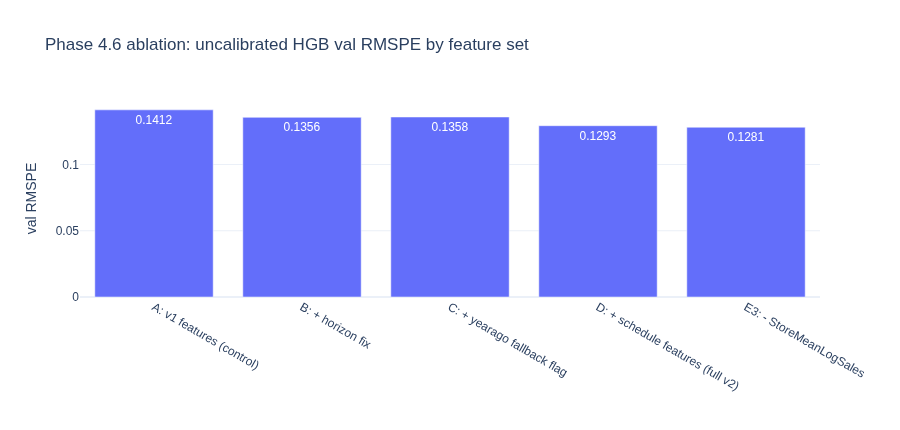


Top 15 features, full v2:
DayOfWeek                 0.152695
Promo                     0.040333
DayOfMonth                0.021087
WasClosedYesterday        0.017052
DaysSincePromo            0.013156
SalesRollMean7            0.006650
LogCompetitionDistance    0.006632
DaysUntilPromo            0.005525
StoreType                 0.005179
DaysUntilSchoolHoliday    0.004653
StoreTrend                0.003700
Promo2WeeksActive         0.003652
WeekOfYear                0.003267
DaysSinceStateHoliday     0.002441
CustomersRollMean7        0.002254


In [8]:
res = pd.Series(results).rename("val_rmspe").to_frame()
control = res["val_rmspe"].iloc[0]
res["delta_vs_control"] = res["val_rmspe"] - control
res["cumulative_gain_%"] = 100 * (control - res["val_rmspe"]) / control
print(res.round(4).to_string())

best_label = res["val_rmspe"].idxmin()
print(f"\nbest feature set: {best_label} at {res['val_rmspe'].min():.4f} "
      f"({res['cumulative_gain_%'].max():.1f}% better than the v1 control)")
print("Phase 1 baseline 0.1448 | Phase 3/4 best 0.1412 | Phase 4.5 calibrated ensemble 0.1257")
print("NB: every number here is UNCALIBRATED single-HGB. Phase 4.5's calibration and")
print("    ensembling stack on top of this and have not been re-applied yet.")

fig = px.bar(res.reset_index(), x="index", y="val_rmspe", text_auto=".4f",
             title="Phase 4.6 ablation: uncalibrated HGB val RMSPE by feature set")
fig.update_layout(height=430, xaxis_title="", yaxis_title="val RMSPE")
fig.show()

print("\nTop 15 features, full v2:")
print(imp_D.head(15).to_string())


In [9]:
# Where did the horizon fix actually change things? Staleness should hurt most at long
# horizons, so that is where training on stale features ought to pay off.
diag = val_fold[["Store", "Date", "Sales", "Open", "DayOfWeek"]].copy()
diag["A_control"] = pred_A
diag["B_horizon"] = pred_B
diag["D_full_v2"] = pred_D
diag["E_best"] = pred_E
diag["horizon_week"] = ((diag["Date"] - CUTOFF).dt.days - 1) // 7 + 1
PRED_COLS = ["A_control", "B_horizon", "D_full_v2", "E_best"]

def by(col):
    return pd.DataFrame({k: {c: rmspe(g["Sales"], g[c]) for c in PRED_COLS}
                         for k, g in diag.groupby(col)}).T

print("RMSPE by horizon week:")
print(by("horizon_week").round(4).to_string())
print("\nRMSPE by DayOfWeek (1=Mon ... 7=Sun):")
print(by("DayOfWeek").round(4).to_string())

# The v1 control was best at week 1 and fell apart later, exactly what a model trained on
# always-fresh features and served stale ones should do. Check that the fix flattened it.
spread = by("horizon_week").agg(lambda s: s.max() - s.min())
print("\nspread across horizon weeks (max-min RMSPE), lower = more horizon-robust:")
print(spread.round(4).to_string())

res.to_csv("phase46_ablation_results.csv")
diag.to_csv("phase46_val_predictions.csv", index=False)
json.dump({"numeric_cols": NUM_BEST, "categorical_cols": TREE_CAT, "best_variant": BEST_LABEL},
          open("phase46_feature_set.json", "w"), indent=2)
print("\nSaved phase46_ablation_results.csv, phase46_val_predictions.csv, phase46_feature_set.json")


RMSPE by horizon week:
   A_control  B_horizon  D_full_v2  E_best
1     0.1081     0.1342     0.1154  0.1126
2     0.1495     0.1464     0.1271  0.1309
3     0.1648     0.1487     0.1481  0.1443
4     0.1339     0.1087     0.1172  0.1193
5     0.1353     0.1192     0.1310  0.1213
6     0.1491     0.1505     0.1339  0.1372

RMSPE by DayOfWeek (1=Mon ... 7=Sun):
   A_control  B_horizon  D_full_v2  E_best
1     0.1149     0.1157     0.1285  0.1228
2     0.1473     0.1298     0.1221  0.1225
3     0.1237     0.1288     0.1174  0.1201
4     0.1303     0.1228     0.1127  0.1108
5     0.1464     0.1559     0.1318  0.1361
6     0.1758     0.1546     0.1566  0.1510
7     0.1589     0.1522     0.1765  0.1644

spread across horizon weeks (max-min RMSPE), lower = more horizon-robust:
A_control    0.0566
B_horizon    0.0418
D_full_v2    0.0327
E_best       0.0317



Saved phase46_ablation_results.csv, phase46_val_predictions.csv, phase46_feature_set.json
